In [1]:
# set up
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%run get_cocorahs_FL-SM_today

http://data.cocorahs.org/export/exportreports.aspx?ReportType=Daily&dtf=1&Format=CSV&State=FL&County=SM&ReportDateType=reportdate&StartDate=01/01/2021&EndDate=11/04/2026&TimesInGMT=False


### Load Data

In [3]:
# define the dates to load in
start_date='01-01-2021'

from datetime import date
today = date.today()
end_date=today.strftime("%m-%d-%Y")

# define the state/county codes to load in
stcode='FL'
ctycode='SM'
datpath='./data/cocorahs_'+stcode+'-'+ctycode+'_'+start_date+'_to_'+end_date+'.csv'

In [4]:
# load the single day data and print the keys
dat=pd.read_csv(datpath)
dat.keys()

Index(['ObservationDate', 'ObservationTime', 'EntryDateTime', 'StationNumber',
       'StationName', 'Latitude', 'Longitude', 'TotalPrecipAmt',
       'NewSnowDepth', 'NewSnowSWE', 'TotalSnowDepth', 'TotalSnowSWE',
       'DateTimeStamp'],
      dtype='object')

In [5]:
# load the multi-day data and print the keys
datmd=pd.read_csv('./data/MultiDayPrecipReports_FL_SM_2021-01-01_1.csv')
datmd.keys()

Index(['StartDate', 'EndDateTime', 'EntryDateTime', 'StationNumber',
       'StationName', 'Latitude', 'Longitude', 'TotalPrecipAmt',
       'TotalSnowDepth', 'TotalSnowSWE', 'DateTimeStamp'],
      dtype='object')

### Get Station Data

In [6]:
# find the station of interest
stnid=' FL-SM-38'
stndat=dat.loc[dat['StationNumber']==stnid]
stndatmd=datmd.loc[datmd['StationNumber']==stnid]
# reverse so that timing is old to new
stndat=stndat.iloc[::-1]
stndatmd=stndatmd.iloc[::-1]

In [7]:
# fill trace results with small amounts
fillTval='0.001'
stndat['TotalPrecipAmt'] = stndat['TotalPrecipAmt'].replace([' T'],fillTval)
# change types for precip and datetime
stndat=stndat.astype({"TotalPrecipAmt": 'float32', "ObservationDate": 'datetime64[ns]'})

In [8]:
# set the time as the index for the observations
dates = pd.DatetimeIndex(stndat['ObservationDate'].values)
stndat.index=dates

### Plot Output

#### Timeseries

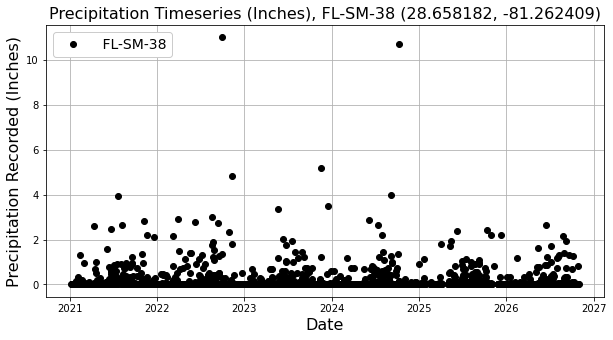

In [9]:
plt.figure(figsize=(10,5),facecolor='w')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'],'o',color='k',markersize=6,label=stnid)
plt.legend(loc='upper left',framealpha=1,fontsize=14)
plt.grid()
plt.xlabel('Date',fontsize=16)
plt.ylabel('Precipitation Recorded (Inches)',fontsize=16)
plt.title('Precipitation Timeseries (Inches),'+stnid+' ('+str(stndat['Latitude'].iloc[0])+', '+str(stndat['Longitude'].iloc[0])+')',fontsize=16)
plt.show()

### Acculumated Rain (All Time)

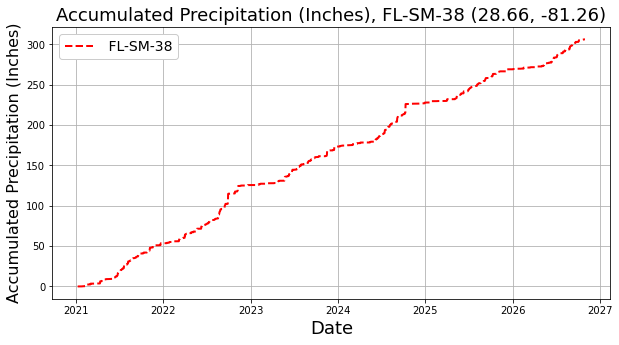

In [10]:
plt.figure(figsize=(10,5),facecolor='w')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].cumsum(),'--',color='r',lw=2,label=stnid)
plt.legend(loc='upper left',framealpha=1,fontsize=14)
plt.grid()
plt.xlabel('Date',fontsize=18)
plt.ylabel('Accumulated Precipitation (Inches)',fontsize=16)
plt.title('Accumulated Precipitation (Inches),'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')', \
         fontsize=18)
plt.show()

In [11]:
stndat['date'] = pd.to_datetime(stndat.ObservationDate)
stndat['year'] = stndat['date'].dt.year
stndat['cumsum'] = stndat.groupby('year')['TotalPrecipAmt'].cumsum()

In [12]:
stndat['year'].unique()[0]

2021

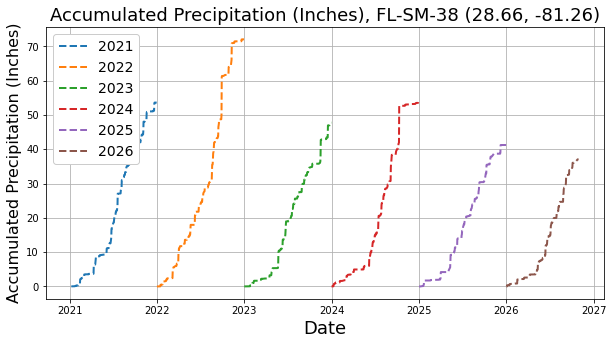

In [13]:
plt.figure(figsize=(10,5),facecolor='w')
for year, group in stndat.groupby('year'):
    plt.plot(group['date'], group['cumsum'], '--', lw=2, label=str(year))
    
#     plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].cumsum(),'--',color='r',lw=2,label=stnid)
plt.legend(loc='upper left',framealpha=1,fontsize=14)
plt.grid()
plt.xlabel('Date',fontsize=18)
plt.ylabel('Accumulated Precipitation (Inches)',fontsize=16)
plt.title('Accumulated Precipitation (Inches),'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')', \
         fontsize=18)
plt.show()

In [14]:
# # Function to generate a complete calendar year
# def generate_full_year(year):
#     return pd.date_range(start=f'{year}-01-01', end=f'{year}-12-31')

In [15]:
# # Create a new DataFrame to hold the reindexed data
# full_data = []

In [16]:
# # Process each year's data
# for year, group in df.groupby('year'):
#     # Generate the full year index
#     full_year_index = generate_full_year(year)
    
#     # Reindex the group's data to the full year, filling with NaN
#     group = group.set_index('date').reindex(full_year_index).reset_index()
    
#     # Rename the columns accordingly
#     group.columns = ['date', 'value', 'year', 'cumsum']
    
#     # Append to the full_data list
#     full_data.append(group)

# # Concatenate all years' data
# full_df = pd.concat(full_data)

# # Extract the day of the year for plotting
# full_df['day_of_year'] = full_df['date'].dt.dayofyear

# # Plot each year's cumulative sum on the same 366-day calendar x-axis
# plt.figure(figsize=(12, 8))

# for year, group in full_df.groupby(full_df['date'].dt.year):
#     plt.plot(group['day_of_year'], group['cumsum'], label=str(year))

### Rainfall Distribution

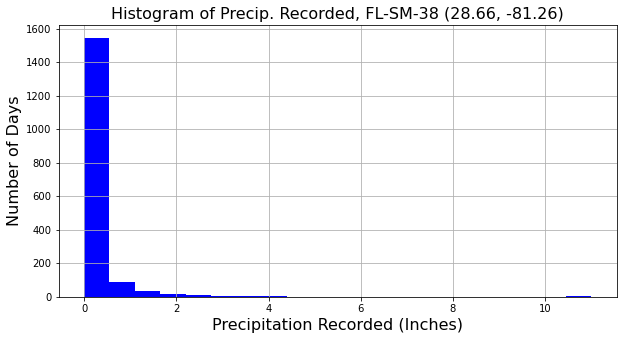

In [17]:
plt.figure(figsize=(10,5),facecolor='w')
stndat['TotalPrecipAmt'].hist(bins=20,color='b')
plt.xlabel('Precipitation Recorded (Inches)',fontsize=16)
plt.ylabel('Number of Days',fontsize=16)
plt.title('Histogram of Precip. Recorded,'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')',fontsize=16)
plt.show()

### Seasonal Accumulation

In [18]:
# calculate each month's cumulative sum
month_long_accumulation=stndat['TotalPrecipAmt'].groupby(stndat['TotalPrecipAmt'].index.to_period('m')).cumsum()
monthly_accumulation=month_long_accumulation[month_long_accumulation.index.is_month_end]
through_today=month_long_accumulation.tail(1)
monthly_accumulation=monthly_accumulation.append(through_today)

<ipython-input-1-49a80917e249>:5: FutureWarning: The series.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  monthly_accumulation=monthly_accumulation.append(through_today)


In [19]:
# get metadata for the plot
nmonvalid=len(monthly_accumulation)
MonthStr=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
if nmonvalid>12:
    nyears=int(np.ceil(nmonvalid/12))
    for i in range(nyears-1):
        for j in range(len(MonthStr)):
            MonthStr.append(MonthStr[j])

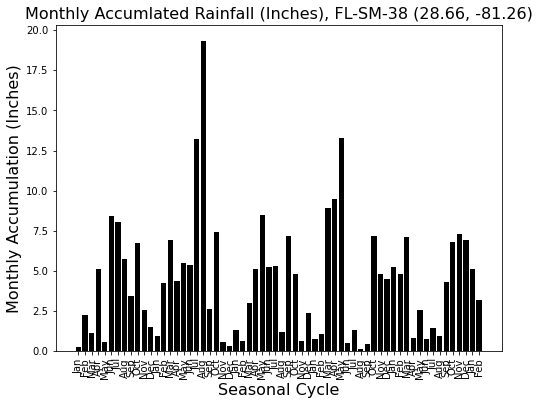

In [20]:
plt.figure(figsize=(8,6),facecolor='w')
plt.bar(np.arange(nmonvalid),monthly_accumulation,color='k')
plt.xlabel('Seasonal Cycle',fontsize=16)
plt.ylabel('Monthly Accumulation (Inches)',fontsize=16)
plt.xticks(np.arange(nmonvalid),MonthStr[:nmonvalid],rotation=90)
plt.title('Monthly Accumlated Rainfall (Inches),'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')',fontsize=16)
plt.show()

### Ranked Days

What days have had the highest record rainfall?

In [21]:
ranked_daily_rainfall=stndat['TotalPrecipAmt'].sort_values(ascending=False)
print('Highest Rainfall days at'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')')
print('-------------------------------------------------')
print('1st: '+str(ranked_daily_rainfall.head(1).values[0])+'" on '+str(ranked_daily_rainfall.head(1).index[0])[:-8])
print('2nd: '+str(ranked_daily_rainfall.head(2).values[1])+'" on '+str(ranked_daily_rainfall.head(2).index[1])[:-8])
print('3rd: '+str(ranked_daily_rainfall.head(3).values[2])+'" on '+str(ranked_daily_rainfall.head(3).index[2])[:-8])
print('4th: '+str(ranked_daily_rainfall.head(4).values[3])+'" on '+str(ranked_daily_rainfall.head(4).index[3])[:-8])
print('5th: '+str(ranked_daily_rainfall.head(5).values[4])+'" on '+str(ranked_daily_rainfall.head(5).index[4])[:-8])


Highest Rainfall days at FL-SM-38 (28.66, -81.26)
-------------------------------------------------
1st: 11.0" on 2022-09-29 
2nd: 10.7" on 2024-10-10 
3rd: 5.18" on 2023-11-17 
4th: 4.81" on 2022-11-10 
5th: 3.98" on 2024-09-05 


###  N-Day Accumulations

<ipython-input-1-f3e0020445e7>:3: MatplotlibDeprecationWarning: Case-insensitive properties were deprecated in 3.3 and support will be removed two minor releases later
  plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'],'o',color='k',MarkerSize=5,label=stnid)


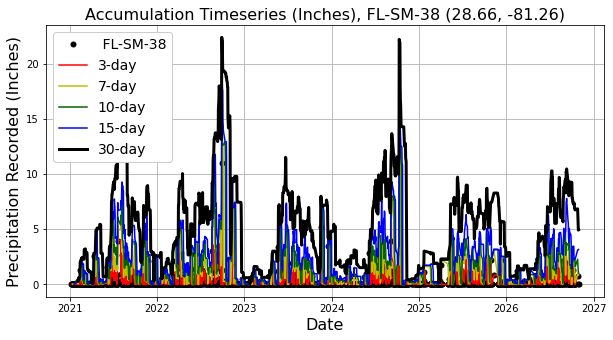

In [22]:
plt.figure(figsize=(10,5),facecolor='w')
# point-by-point
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'],'o',color='k',MarkerSize=5,label=stnid)
# N-day running accumulations
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].rolling(3).sum(),color='r',label='3-day')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].rolling(7).sum(),color='y',label='7-day')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].rolling(10).sum(),color='darkgreen',label='10-day')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].rolling(15).sum(),color='b',label='15-day')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].rolling(30).sum(),color='k',label='30-day',lw=3)

plt.legend(loc='upper left',framealpha=1,fontsize=14)
plt.grid()
plt.xlabel('Date',fontsize=16)
plt.ylabel('Precipitation Recorded (Inches)',fontsize=16)
plt.title('Accumulation Timeseries (Inches),'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')',fontsize=16)
plt.show()

### Consecutive Dry Days

Calculate the number of rain days as:
- 0, if precipitation == 0
- 1, if precipitation > 0

And dry days are the opposite.

In [23]:
# get the boolean of True for rain > 0, False for rain == 0
rain_days=(stndat['TotalPrecipAmt']>0)
dry_days=~(stndat['TotalPrecipAmt']>0)
# find the number of rain days, total observations, and dry days
nraindays=rain_days.sum()
nobs=len(stndat['TotalPrecipAmt'])
raindays_perc=rain_days.sum()/nobs
ndrydays=dry_days.sum()
# print the result
print('It has rained '+str(int(nraindays))+' days out of '+str(int(nobs))+' recorded, i.e. '+str(100*round(raindays_perc,3))+'% of days')


It has rained 727 days out of 1710 recorded, i.e. 42.5% of days


In [24]:
# create a function to calculate consective dry days
def cdd_calc(drydays_boolean):
    
    # setup
    count = 0
    nobs=len(drydays_boolean)
    cdd=np.zeros((nobs,),dtype='float64')
    
    # loop over timeseries
    for i in range(nobs):

        if drydays_boolean[i]==True:
            count += 1
        elif drydays_boolean[i]==False and count>0:
            count = 0
            
        # store the count
        cdd[i,]=count
        
    # return to above program level
    return(cdd)

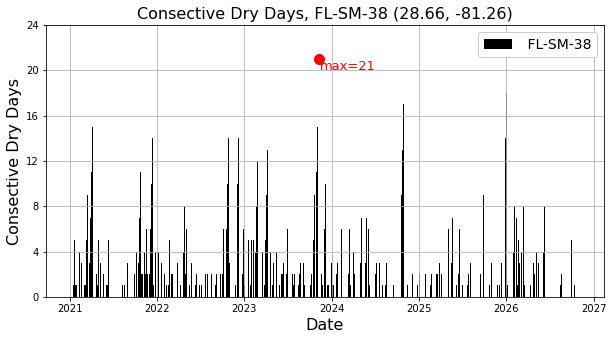

In [25]:
# calculate the number of consecutive dry days
cdd=cdd_calc(dry_days)

# plot the result
plt.figure(figsize=(10,5),facecolor='w')
plt.bar(stndat['TotalPrecipAmt'].index,cdd,color='k',label=stnid)
# plot the maximum
cddmaxloc=np.argmax(cdd)
plt.plot(stndat['TotalPrecipAmt'].index[cddmaxloc],cdd[cddmaxloc],'o',color='r',markersize=10)
plt.text(stndat['TotalPrecipAmt'].index[cddmaxloc+1],cdd[cddmaxloc]-1,'max='+str(int(cdd[cddmaxloc])),fontsize=13,color='r')

plt.legend(loc='upper right',framealpha=1,fontsize=14)
plt.grid()
plt.xlabel('Date',fontsize=16)
plt.yticks(np.arange(0,cdd[cddmaxloc]+4,4))
plt.ylabel('Consective Dry Days',fontsize=16)
plt.title('Consective Dry Days,'+stnid+' ('+str(stndat['Latitude'].iloc[0].round(2))+', '+str(stndat['Longitude'].iloc[0].round(2))+')',fontsize=16)
plt.show()

## Correlation with nearby stations

In [26]:
def calculate_distance(i,dat,mylat,mylon):
    # import what we need
    from haversine import haversine, Unit
    
    # find the lat/lon for this station
    thislat=dat['Latitude'].loc[dat['StationNumber']==stn_names[i,]].values[0]
    thislon=dat['Longitude'].loc[dat['StationNumber']==stn_names[i,]].values[0]
    
    # define the locations
    thisloc=(thislat,thislon)
    myloc=(mylat,mylon)
    
    # calculate the distance in miles with the haversine formula
    thisdist=haversine(myloc, thisloc, unit=Unit.MILES)
    
    # go back to the above program level
    return(thisdist)

In [27]:
# import what we need
import scipy

# find all the nearby station names and how many there are
stn_names=dat['StationNumber'].unique()
nstn=len(stn_names)

# find the lat/lon for the FL-SM-38 station
mylat=stndat['Latitude'].values[0]
mylon=stndat['Longitude'].values[0]

# create the arrays we need
stndist=np.empty((nstn,),dtype='float64')
stnnobs=np.empty((nstn,),dtype='int')

# loop over all of the stations
for i in range(nstn):
    
    # grab this station's data
    thisdat=dat.loc[dat['StationNumber']==stn_names[i,]]
    
    # calculate distance between this station and FL-SM-38
    dist=calculate_distance(i,dat,mylat,mylon)
    stndist[i,]=dist
    
    # find the number of individual daily observations for this station
    stnnobs[i,]=len(thisdat['ObservationDate'].unique())
    
    # calculate the station correlations
    #rval=scipy.stats.pearsonr()
    

/Users/dgilford/opt/anaconda3/lib/python3.8/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [28]:
# sort the results for stations by distance
distsortedi=np.argsort(stndist)

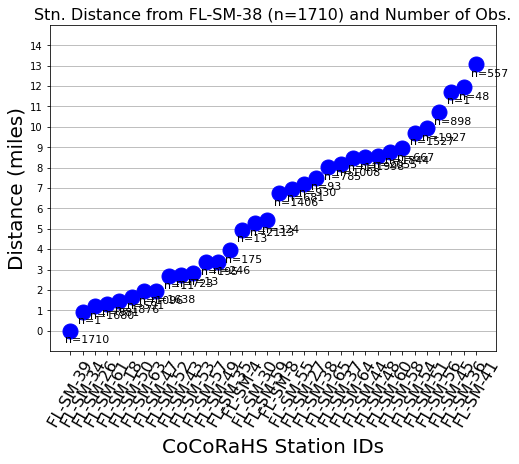

In [29]:
# plot the distances, sorted, and number of observations over the period
plt.figure(figsize=(8,6),facecolor='w')
plt.plot(np.arange(nstn),stndist[distsortedi],'o',color='b',markersize=15)
for i in range(nstn):
    plt.text(i-0.4,stndist[distsortedi][i]-0.6,'n='+str(stnnobs[distsortedi][i]),fontsize=11)
plt.xlabel('CoCoRaHS Station IDs',fontsize=20)
plt.xticks(np.arange(nstn),labels=stn_names,rotation=60,fontsize=16)
plt.ylim([-1,np.max(np.ceil(stndist))+1])
plt.yticks(np.arange(np.max(np.ceil(stndist))+1))
plt.ylabel('Distance (miles)',fontsize=20)
plt.grid(axis='y')
plt.title('Stn. Distance from FL-SM-38 (n='+str(int(len(stndat['ObservationDate'].unique()))) \
                                                +') and Number of Obs.',fontsize=16)
plt.show()

## Nearby Station -- ORLANDO INTERNATIONAL AIRPORT, FL US (USW00012815)

In [30]:
# load the data
ghcn_path='./data/ghcn/2598780.csv'
ghcndat=pd.read_csv(ghcn_path)

ghcn_daily_path='./data/ghcn/2613002.csv'
ghcndaily=pd.read_csv(ghcn_daily_path)

In [31]:
# Function to organize the data's time grids with datetime formats
def get_dt64(df,colname='DATE'):
    from datetime import datetime
    # ds is an input panda dataframe with dimension/variable in colname
    # grab and reformat the time index from the netcdf files
    inttime=df[colname]
    # convert to dt64
    dt64=[np.datetime64(datetime.strptime(i, '%Y-%m-%d')) for i in inttime]
    dt64=np.asarray(dt64)
    return(dt64)

# re-index the data with datetime
out=get_dt64(ghcndat,colname='DATE')
ghcndat['datetime']=out
ghcndat.index=ghcndat['datetime']

stnname=ghcndat['NAME'].head(1).values[0]

out2=get_dt64(ghcndaily,colname='DATE')
ghcndaily['datetime']=out2
ghcndaily.index=ghcndaily['datetime']

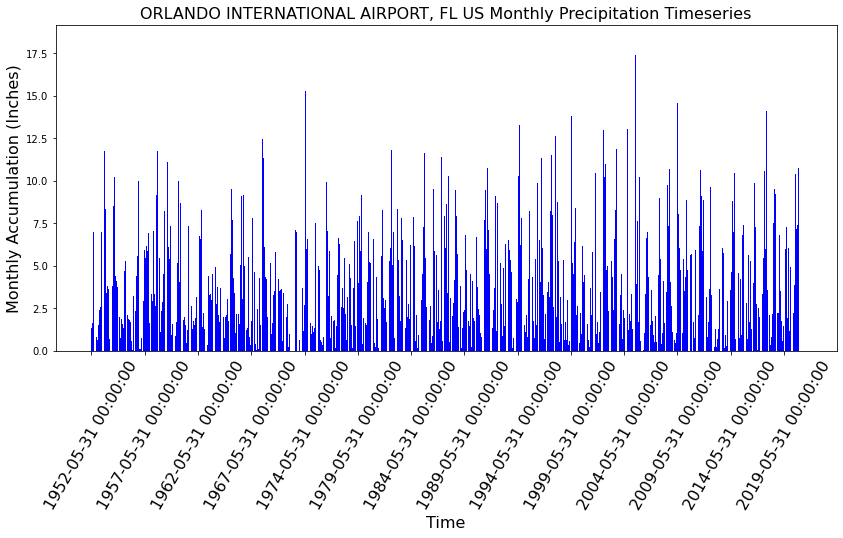

In [32]:
# get the monthly accumulation
ghcn_month_long_accumulation=ghcndat['PRCP'].groupby(ghcndat['PRCP'].index.to_period('m')).cumsum()
ghcn_monthly_accumulation=ghcn_month_long_accumulation[ghcn_month_long_accumulation.index.is_month_end]
# plot the result
plt.figure(figsize=(14,6))
plt.bar(np.arange(len(ghcn_monthly_accumulation)),ghcn_monthly_accumulation.values,color='b')
plt.ylabel('Monthly Accumulation (Inches)',fontsize=16)
plt.xlabel('Time',fontsize=16)
plt.xticks(np.arange(len(ghcn_monthly_accumulation))[0::12*5],labels=ghcn_monthly_accumulation.index[0::12*5],rotation=60,fontsize=16)
plt.title(stnname+' Monthly Precipitation Timeseries',fontsize=16)
plt.show()

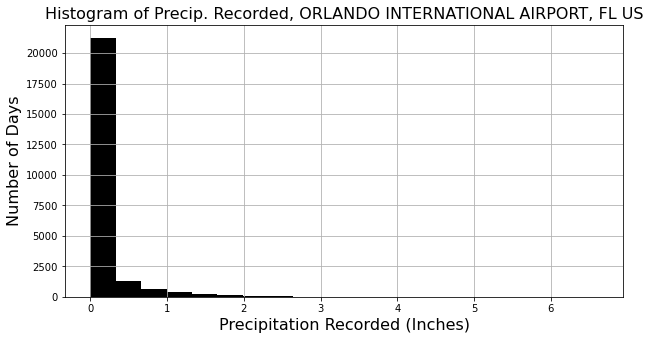

In [33]:
plt.figure(figsize=(10,5),facecolor='w')
ghcndat['PRCP'].hist(bins=20,color='k')
plt.xlabel('Precipitation Recorded (Inches)',fontsize=16)
plt.ylabel('Number of Days',fontsize=16)
plt.title('Histogram of Precip. Recorded, '+stnname,fontsize=16)
plt.show()

In [34]:
nmon=12
annual_precip_mean=np.zeros((nmon,),dtype='float')
for m in range(12):
    annual_precip_mean[m,]=ghcn_monthly_accumulation.groupby(ghcn_monthly_accumulation.index.month == m+1).mean()[1]

ValueError: The number of FixedLocator locations (12), usually from a call to set_ticks, does not match the number of ticklabels (384).

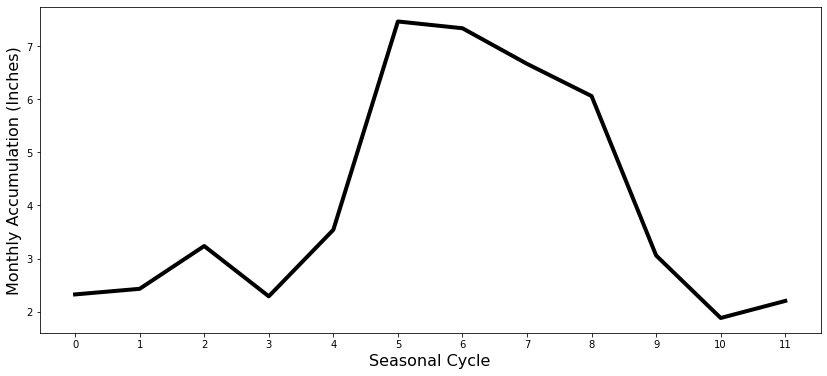

In [35]:
plt.figure(figsize=(14,6),facecolor='w')
plt.plot(np.arange(nmon),annual_precip_mean,color='k',lw=4)
plt.xlabel('Seasonal Cycle',fontsize=16)
plt.ylabel('Monthly Accumulation (Inches)',fontsize=16)
plt.xticks(np.arange(nmon),MonthStr)
plt.title('Mean Seasonal Cycle of Monthly Accumlated Rainfall (Inches), '+stnname,fontsize=16)
plt.grid()
plt.show()

ValueError: The number of FixedLocator locations (12), usually from a call to set_ticks, does not match the number of ticklabels (384).

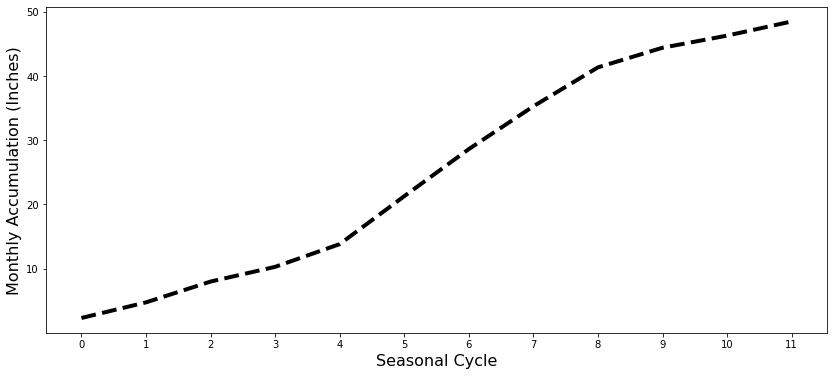

In [36]:
plt.figure(figsize=(14,6),facecolor='w')
plt.plot(np.arange(nmon),annual_precip_mean.cumsum(),'--',color='k',lw=4)
plt.xlabel('Seasonal Cycle',fontsize=16)
plt.ylabel('Monthly Accumulation (Inches)',fontsize=16)
plt.xticks(np.arange(nmon),MonthStr)
plt.title('Mean Annual Accumlated Rainfall (Inches), '+stnname,fontsize=16)
plt.grid()
plt.show()

## Plot against OIA

In [37]:
deficit=(annual_precip_mean.cumsum()[5])-stndat['TotalPrecipAmt'].cumsum().max()
deficit_percentage=deficit/((annual_precip_mean.cumsum()[4]+annual_precip_mean.cumsum()[5])/2)*100
if deficit>0:
    print('FL-SM-38 is missing '+str(np.round(deficit,2))+' inches of rain, relative to the OIA average at the end of June')
    print('This is about a '+str(int(np.round(deficit_percentage,0)))+'% deficit')
else:
    print('FL-SM-38 exceeds the OIA average rain by '+str(np.round(-deficit,2))+' inches')
    print('This is about a '+str(int(np.round(-deficit_percentage,0)))+'% surplus')

FL-SM-38 exceeds the OIA average rain by 284.92 inches
This is about a 1623% surplus


In [38]:
from datetime import datetime, timedelta
tmon= np.arange(datetime(2021,1,31), datetime(2021,12,31), timedelta(days=30)).astype(datetime)

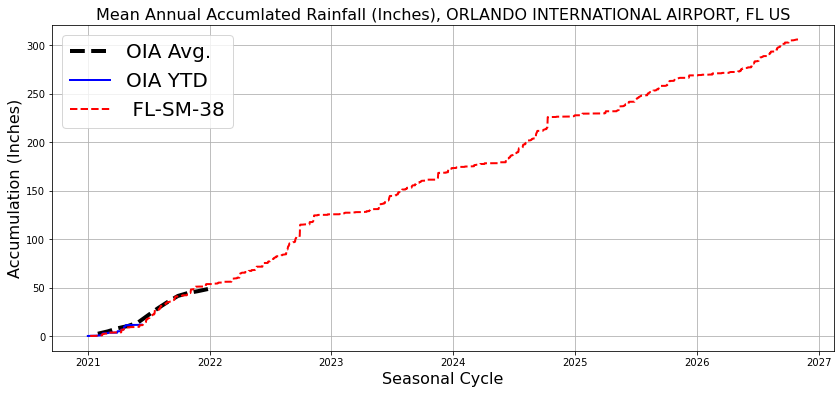

In [39]:
plt.figure(figsize=(14,6),facecolor='w')
plt.plot(tmon,annual_precip_mean.cumsum(),'--',color='k',lw=4,label='OIA Avg.')
plt.plot(ghcndaily.index,ghcndaily['PRCP'].cumsum(),color='b',lw=2,label='OIA YTD')
plt.plot(stndat['TotalPrecipAmt'].index,stndat['TotalPrecipAmt'].cumsum(),'--',color='r',lw=2,label=stnid)
plt.xlabel('Seasonal Cycle',fontsize=16)
plt.ylabel('Accumulation (Inches)',fontsize=16)
plt.title('Mean Annual Accumlated Rainfall (Inches), '+stnname,fontsize=16)
plt.legend(fontsize=20)
plt.grid()
plt.show()

## Power Law Fit?

In [40]:
break_here

NameError: name 'break_here' is not defined

In [41]:
xdata=np.linspace(0,stndat['TotalPrecipAmt'].max()+0.1,100)
ydata,bin_edges=np.histogram(stndat['TotalPrecipAmt'],bins=xdata)
yerr=0.01 * ydata

[ 1. -1.]
None


<ipython-input-1-38c17911fcff>:13: RuntimeWarning: divide by zero encountered in log10
  logx = np.log10(xdata[:-1])
<ipython-input-1-38c17911fcff>:14: RuntimeWarning: divide by zero encountered in log10
  logy = np.log10(ydata)
<ipython-input-1-38c17911fcff>:15: RuntimeWarning: invalid value encountered in divide
  logyerr = yerr / ydata


NameError: name 'powerlaw' is not defined

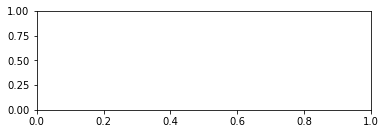

In [42]:
# Fitting the data -- Least Squares Method
##########

# Power-law fitting is best done by first converting
# to a linear equation and then fitting to a straight line.
# Note that the `logyerr` term here is ignoring a constant prefactor.
#
#  y = a * x^b
#  log(y) = log(a) + b*log(x)
#
from scipy import optimize

logx = np.log10(xdata[:-1])
logy = np.log10(ydata)
logyerr = yerr / ydata

# define our (line) fitting function
fitfunc = lambda p, x: p[0] + p[1] * x
errfunc = lambda p, x, y, err: (y - fitfunc(p, x)) / err

pinit = [1.0, -1.0]
out = optimize.leastsq(errfunc, pinit,
                       args=(logx, logy, logyerr), full_output=1)

pfinal = out[0]
covar = out[1]
print(pfinal)
print(covar)

index = pfinal[1]
amp = 10.0**pfinal[0]

#indexErr = np.sqrt( covar[1][1] )
#ampErr = np.sqrt( covar[0][0] ) * amp

##########
# Plotting data
##########

plt.clf()
plt.subplot(2, 1, 1)
plt.plot(xdata, powerlaw(xdata, amp, index))     # Fit
plt.errorbar(xdata, ydata, yerr=yerr, fmt='k.')  # Data
plt.text(5, 6.5, 'Ampli = %5.2f +/- %5.2f' % (amp, ampErr))
plt.text(5, 5.5, 'Index = %5.2f +/- %5.2f' % (index, indexErr))
plt.title('Best Fit Power Law')
plt.xlabel('X')
plt.ylabel('Y')
plt.xlim(1, 11)

plt.subplot(2, 1, 2)
plt.loglog(xdata, powerlaw(xdata, amp, index))
plt.errorbar(xdata, ydata, yerr=yerr, fmt='k.')  # Data
plt.xlabel('X (log scale)')
plt.ylabel('Y (log scale)')
plt.xlim(1.0, 11)

In [43]:
len(y)

NameError: name 'y' is not defined

In [44]:
# Define function for calculating a power law
powerlaw = lambda x, amp, index: amp * (x**index)
xdata = np.linspace(1.1, 10.1, 100) 
ydata = powerlaw(xdata, 10.0, -2.0)     # simulated perfect data
yerr = 0.2 * ydata                      # simulated errors (10%)
ydata += np.random.randn(100) * yerr       # simulated noisy data

In [45]:
xdata=np.linspace(0,stndat['TotalPrecipAmt'].max()+0.1,100)
vals,bin_edges=np.histogram(stndat['TotalPrecipAmt'],bins=xdata)

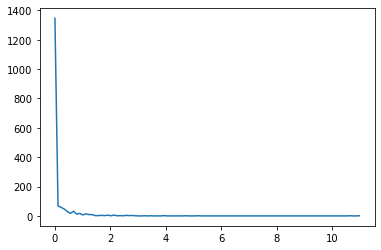

In [46]:
plt.plot(bin_edges[:-1],vals)